# Ioannou_Georgios


<h1 align="center"> Decision Trees (DT) and Random Forests (RF) Exercise </h1>
    

<p style="text-align:center;">Run this notebook from top to bottom. In each <b style="color:#E67E22;">Your turn</b> cell, write your code under the comment.</p>


<h2 align="center"> Libraries </h2>


<div style="background-color:#EAF3FB; color:#1a1a1a !important; border-left:6px solid #2471A3; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#2471A3 !important;">Provided.</b> <span style="color:#1a1a1a !important;"> Run this provided code.</span></p>
</div>


In [2]:
pip install graphviz

In [3]:
# import libraries.

# Use inline so our visualizations display in notebook.

%matplotlib inline

import graphviz                 # graphviz for visualizing our tree.
import matplotlib.pyplot as plt # matplotlib for visualization.
import numpy as np              # numpy for data wrangling.
import pandas as pd             # pandas for data wrangling.
import seaborn as sns           # seaborn for visualization.
sns.set()


from sklearn.tree import DecisionTreeClassifier      # import our Decision Tree.
from sklearn.model_selection import GridSearchCV     # helper function for hyper-parameter turning.
from sklearn.ensemble import RandomForestClassifier  # import our Random Forest.
from sklearn.model_selection import train_test_split # helper function to split our data.
from sklearn import tree                             # import the trees from sklearn.
# helper fuctions to evaluate our model.
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score


<h2 align="center"> Remember our main steps motto "ISBE". </h2>

<h3 align="center"> Main Steps when building a Machine Learning Model. </h3>

1. <b>I</b> - Inspect and explore data.
2. <b>S</b> - Select and engineer features.
3. <b>B</b> - Build and train model.
4. <b>E</b> - Evaluate model.


## #1 Inspect and Explore Data

1. Load titanic data.
2. Visualize all the data using sns.pairplot.
3. Check for null values.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Load in the titanic data set.<br>Read the file titanic.csv located inside the data folder and then load the data.<br>Print/Display/Return the first 5 rows of the file titanic.csv to make sure the file was loaded successfully.</span></p>
</div>


In [4]:
# 1. Load in the titanic data set.
#    Read the file titanic.csv located inside the data folder and then load the data.
df = pd.read_csv('../data/titanic.csv')
# Print/Display/Return the first 5 rows of the file titanic.csv to make sure the file was loaded successfully.
df.head(5)

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Visualize all the data using sns.pairplot.</span></p>
</div>


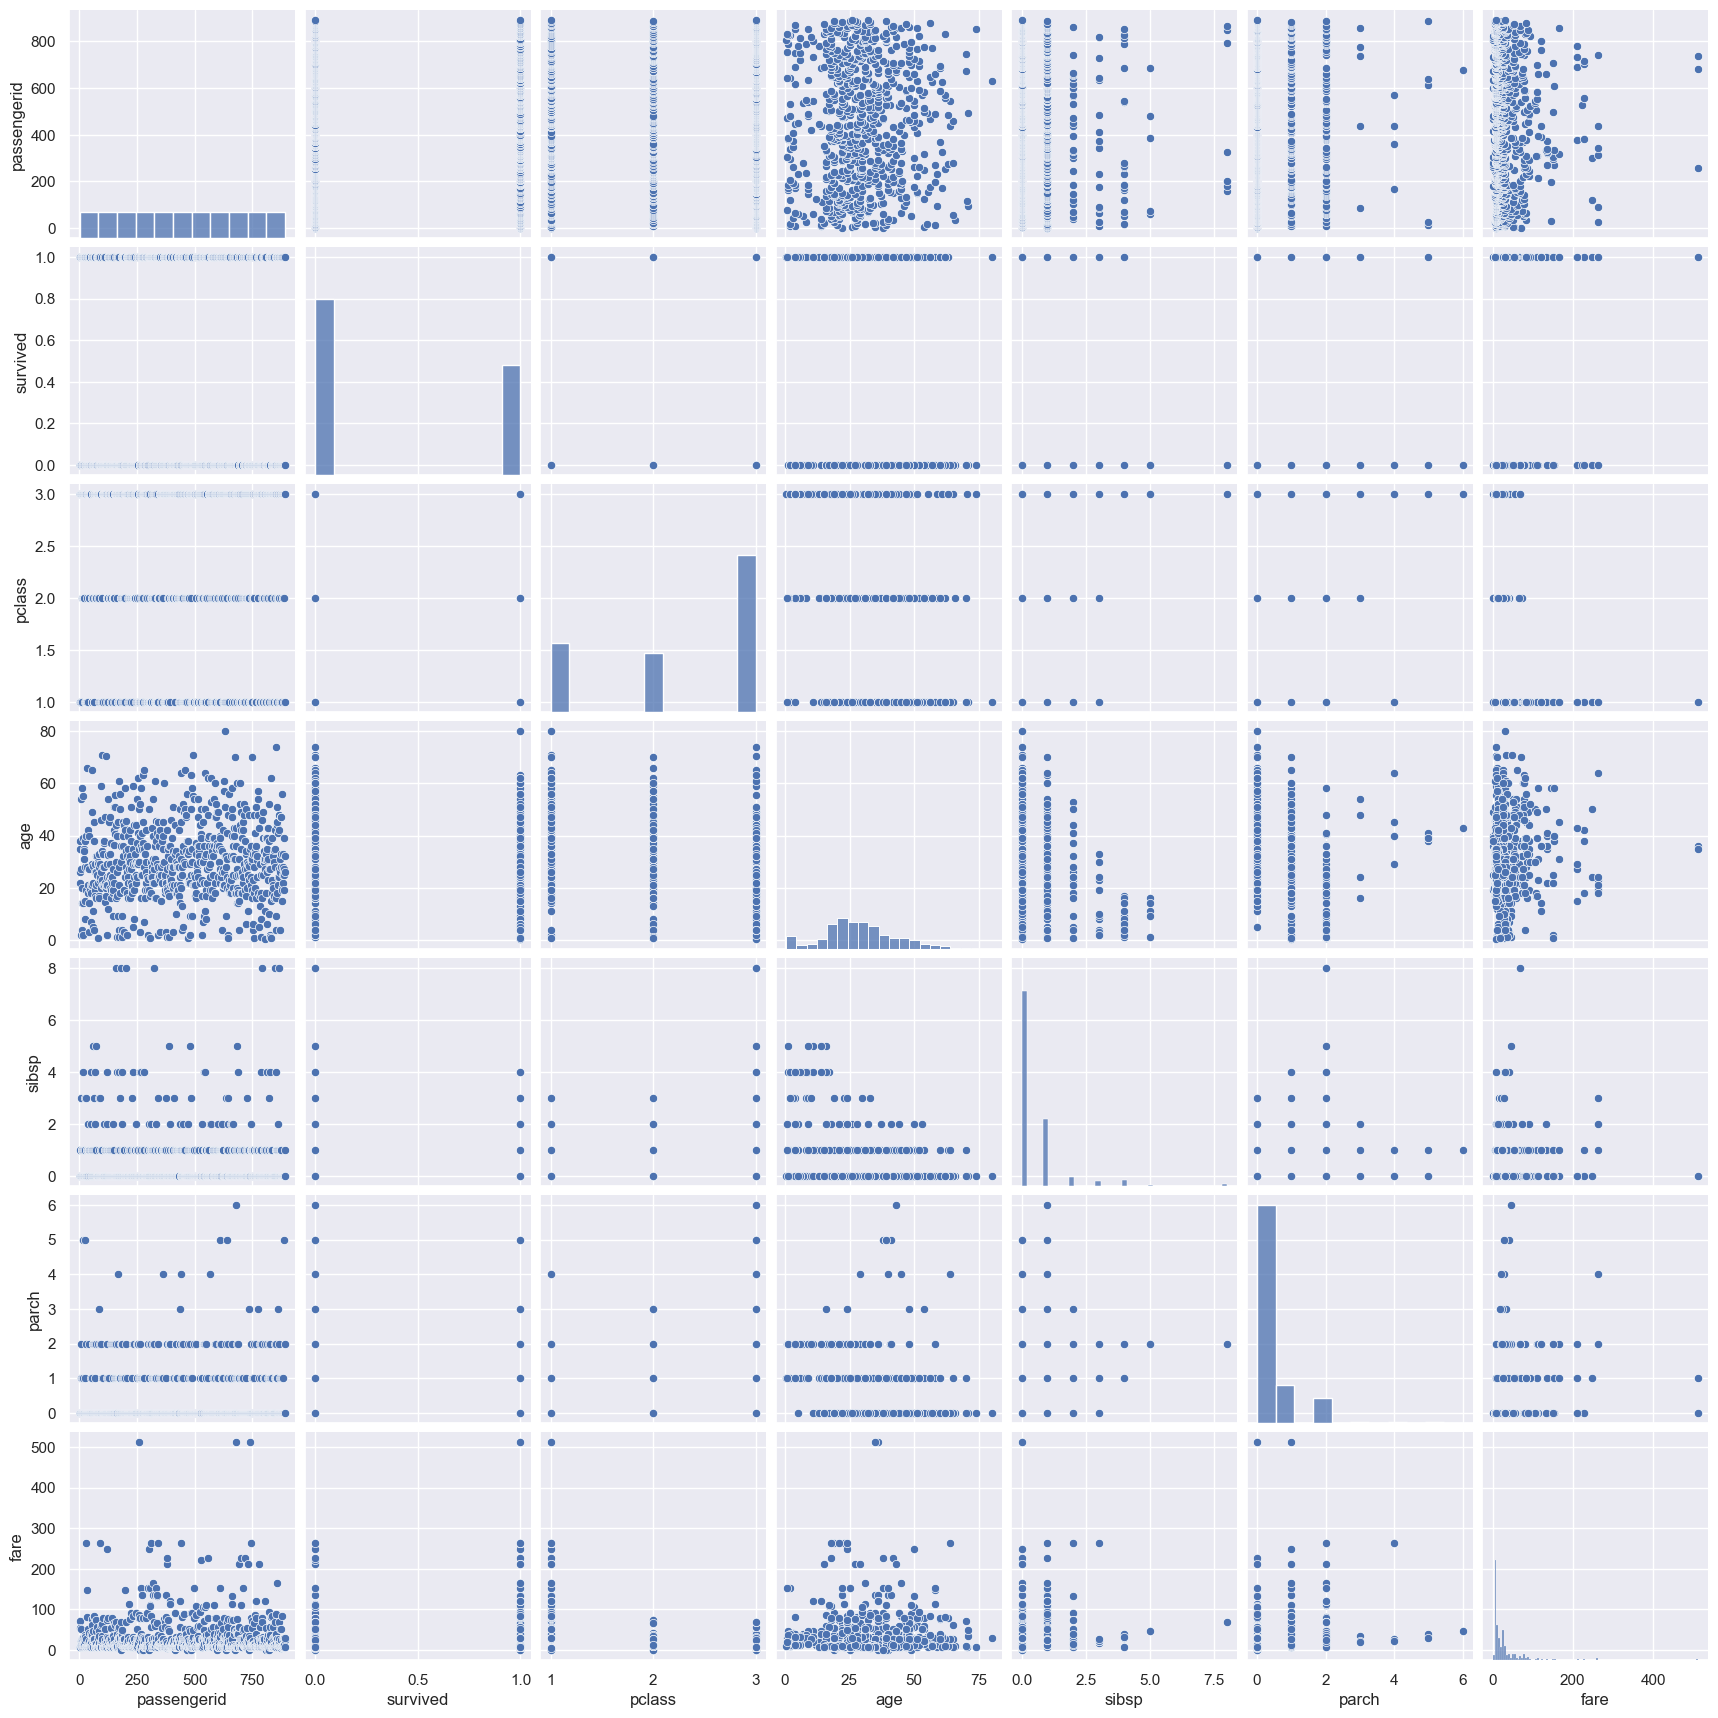

In [5]:
# 2. Visualize all the data using sns.pairplot.
sns.pairplot(df)
plt.show()

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Check for null values.</span></p>
</div>


In [6]:
# 3. Check for null values.
df.isnull().sum()

passengerid      0
survived         0
pclass           0
name             0
sex              0
age            177
sibsp            0
parch            0
ticket           0
fare             0
cabin          687
embarked         2
dtype: int64

## #2 Select and Engineer Features

1. Fill age null values with -999.
2. Convert to numerical values if needed be by using `pd.get_dummies()`.
3. Create a list of the features you are going to use.  In this case use as many or as little as you would like.
4. Define our `X` and `y`.
5. Split our data into trainig and testing sets.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Fill age null values with -999.</span></p>
</div>


In [7]:
# 1. Fill age null values with -999.
df['age'] = df['age'].fillna(-999)

In [8]:
# 1.1. Engineer the rest of the  features for X

# Fill missing 'embarked' with the most frequent port ('S')
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# Engineer 'cabin': Create a binary feature (1 if they had a cabin, 0 if NaN)
df['has_cabin'] = df['cabin'].notnull().astype(int)


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Convert to numerical values if needed be by using `pd.get_dummies()`.</span></p>
</div>


In [9]:
# 2. Convert to numerical values if needed be by using `pd.get_dummies()`.

# Drop the columns we don't need
df = df.drop(['name', 'cabin', 'passengerid', 'ticket'], axis=1)

# Now apply get_dummies to convert categorical into numerical values
df = pd.get_dummies(df, drop_first=True)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> Print/Display/Return the first 5 rows of the file titanic.csv to see the data and selected features.</span></p>
</div>


In [10]:
# Print/Display/Return the first 5 rows of the file titanic.csv to see the data and selected features.
df.head(5)

,survived,pclass,age,sibsp,parch,fare,has_cabin,sex_male,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,0,True,False,True
1,1,1,38.0,1,0,71.2833,1,False,False,False
2,1,3,26.0,0,0,7.9250,0,False,False,True
3,1,1,35.0,1,0,53.1000,1,False,False,True
4,0,3,35.0,0,0,8.0500,0,True,False,True


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Create a list of the features we are going to use.</span></p>
</div>


In [11]:
# 3. Create a list of the features we are going to use.
df_selected = [col for col in df.columns if col != 'survived']
df_selected

['pclass',
 'age',
 'sibsp',
 'parch',
 'fare',
 'has_cabin',
 'sex_male',
 'embarked_Q',
 'embarked_S']

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Define our `X` and `y`. The target column for `y` is `survived`.</span></p>
</div>


In [12]:
# 4. Define our `X` and `y`.
X = df[df_selected]
y = df['survived']

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 5. Split our data into trainig and testing sets.</span></p>
</div>


In [13]:
# 5. Split our data into trainig and testing sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## #3 Build and Train Model

1. For our first pass, initialize our model with `max_depth=2`.
2. Fit our model with our training data. 
3. Make predictions of our testing data.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. For our first pass, initialize our model with `max_depth=2`.</span></p>
</div>


In [14]:
# 1. For our first pass, initialize our model with `max_depth=2`.
model = DecisionTreeClassifier(max_depth=2, random_state=42)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Fit our model with our training data.</span></p>
</div>


In [15]:
# 2. Fit our model with our training data. 
model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Make predictions of our testing data.</span></p>
</div>


In [16]:
# 3. Make predictions of our testing data. 
y_pred = model.predict(X_test)

## #4 Evaluate Model

1. Evaluate and print our model scores using accuracy, precision, recall, f1 scores, and auc scores. 
    * To calculate auc score you have to get the predicted probabilites for the Survived class using `model.predict_proba(X_test)[:,1]`
2. Visualize our Decision Tree using provided code.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Evaluate and print our model scores using accuracy, precision, recall, f1 scores, and auc scores.<br>Calculate predicted probabilities.<br>Keep only the probabilities for True.<br>Compute auc score.</span></p>
</div>


In [17]:
# 1. Evaluate and print our model scores using accuracy, precision, recall, f1 scores, and auc scores.
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
# Calculate predicted probabilities.

y_prob = model.predict_proba(X_test)
# Keep only the probabilities for True.

y_prob = y_prob[:,1]
# Compute auc score.
auc = roc_auc_score(y_test, y_pred)
print(f"AUC Score: {auc}")

Accuracy:  0.7765
Precision: 0.9394
Recall:    0.4493
F1 Score:  0.6078
AUC Score: 0.7155467720685112


<div style="background-color:#EAF3FB; color:#1a1a1a !important; border-left:6px solid #2471A3; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#2471A3 !important;">Provided.</b> <span style="color:#1a1a1a !important;"> Run this provided code.</span></p>
</div>


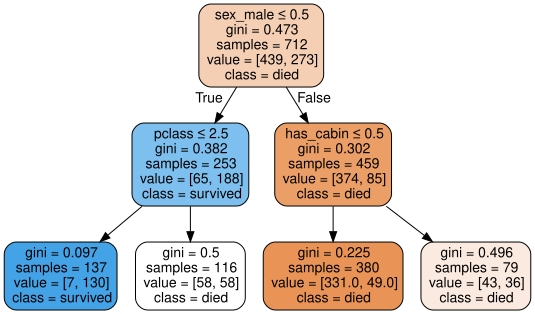

In [ ]:
# 2. Visualize your decision tree.

dot_data = tree.export_graphviz(model, out_file=None, 
                     feature_names=df_selected,
                     class_names=['died','survived'],
                     filled=True, rounded=True,  
                     special_characters=True)  
graph = graphviz.Source(dot_data)
graph


## Picking the right parameters...

## Parameter tuning of your Decision Tree using GridSearch

1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
2. Initalize your GridSearchCV with a DecisionTreeClassifier, your param_grid, and what you are optimizing for.  Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
3. Fit your GridSearchCV with your training data. 
4. Print the parameters of your best model. 
5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
6. Visualize your best tree.
7. Which feature was your most important feature?

```python
tree.DecisionTreeClassifier(
    *,
    criterion='gini',
    splitter='best',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features=None,
    random_state=None,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    min_impurity_split=None,
    class_weight=None,
    presort='deprecated',
    ccp_alpha=0.0,
)
```


[Tips on how to customize / set the paramters in the decision tree.](https://scikit-learn.org/stable/modules/tree.html#tips-on-practical-use)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.</span></p>
</div>


In [19]:
# 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 5, 10, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Initalize your GridSearchCV with a DecisionTreeClassifier, your param_grid, and what you are optimizing for.<br>Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.</span></p>
</div>


In [20]:
# 2. Initalize your GridSearchCV with a DecisionTreeClassifier, your param_grid, and what you are optimizing for.
#    Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=1
)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Fit your GridSearchCV with your training data.</span></p>
</div>


In [21]:
# 3. Fit your GridSearchCV with your training data. 
grid_search.fit(X_train, y_train)

,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [2, 5, ...], 'min_samples_leaf': [1, 5, ...], 'min_samples_split': [2, 10, ...]}"
,scoring,'f1'
,n_jobs,1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'entropy'


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Print the parameters of your best model.<br>Print the best parameters it found.</span></p>
</div>


In [22]:
# 4. Print the parameters of your best model. 
#    Print the best parameters it found.
print("Best parameters: ", grid_search.best_params_)

Best parameters:  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 20}


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores.<br>What do you expect the best model from your search to be, and what will you try so you can evaluate it?<br>Now lets evaluate our model.<br>Calculate predicted probabilities, keep only probability for when class = 1.</span></p>
</div>


In [23]:
# 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
# This command gives you the best Tree.
model = grid_search.best_estimator_

# Now lets evaluate our model.
y_pred = model.predict(X_test)
# Calculate predicted probabilities, keep only probability for when class = 1.
y_prob = model.predict_proba(X_test)[:, 1]

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Accuracy:  0.7877
Precision: 0.7541
Recall:    0.6667
F1 Score:  0.7077
AUC Score: 0.8068


<div style="background-color:#EAF3FB; color:#1a1a1a !important; border-left:6px solid #2471A3; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#2471A3 !important;">Provided.</b> <span style="color:#1a1a1a !important;"> Run this provided code.</span></p>
</div>


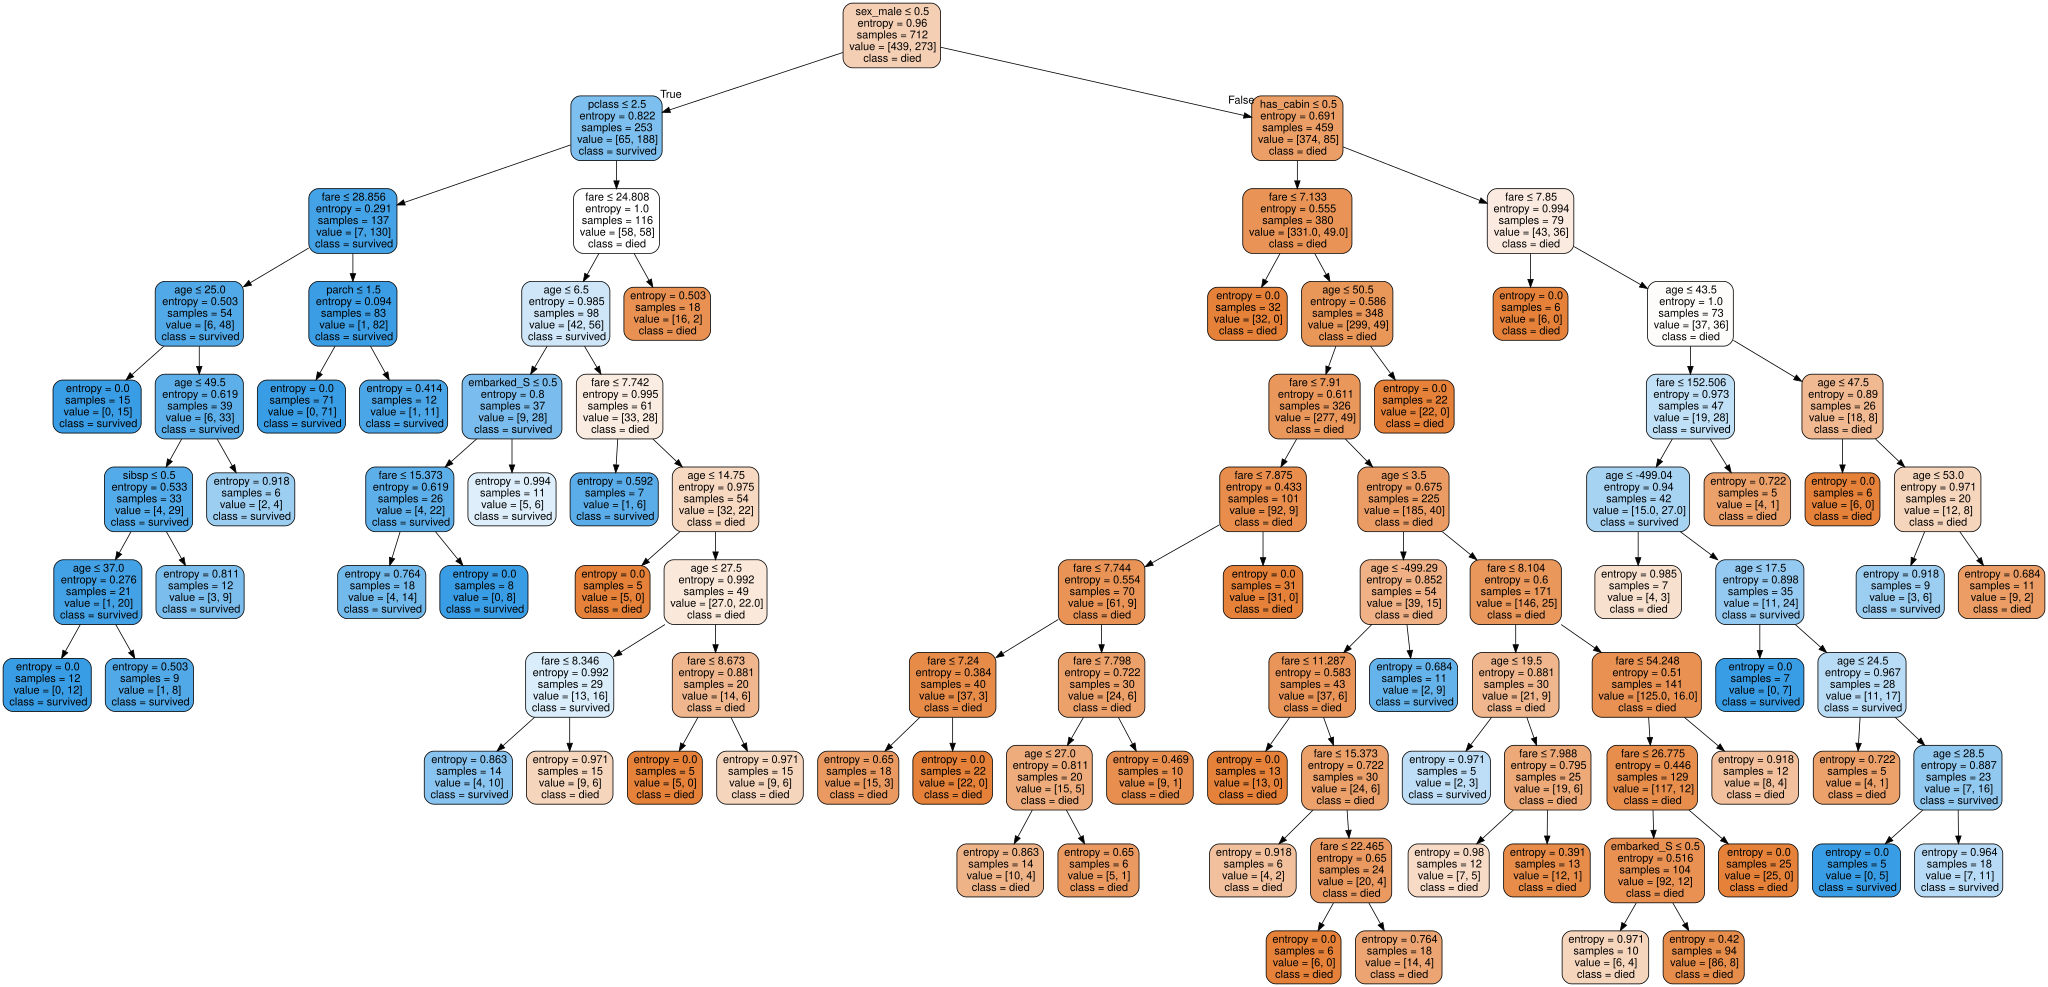

In [24]:
# 6. Visualize your best tree.

dot_data = tree.export_graphviz(model, out_file=None, 
                     feature_names=df_selected,
                     class_names=['died','survived'],
                     filled=True, rounded=True,  
                     special_characters=True)  
graph = graphviz.Source(dot_data)
graph


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 7. Which feature was your most important feature?<br>Now lets look at our feature importances.</span></p>
</div>


In [25]:
# 7. Which feature was your most important feature?
#    Now lets look at our feature importances.


***
<h1 align="center"> <span style="color:#FFA500"> Which feature was your most important feature? </span> </h1>

***
<p style="text-align:center;">Write your answer in this cell after the table above.</p>


## Now onto Random Forests...
### We are going to do the same, but this time with a Random Forest. Remeber... Repetition is the father of learning.

1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.  Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
3. Fit your GridSearchCV with your training data. 
4. Print the parameters of your best model. 
5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
6. Which feature was your most important feature?


## Parameters of the Random Forest Classifier

```python
RandomForestClassifier(
    n_estimators=100,
    *,
    criterion='gini',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features='auto',
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    min_impurity_split=None,
    bootstrap=True,
    oob_score=False,
    n_jobs=None,
    random_state=None,
    verbose=0,
    warm_start=False,
    class_weight=None,
    ccp_alpha=0.0,
    max_samples=None,
)
```

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.</span></p>
</div>


In [26]:
# 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 10, 20],
    'max_features': ['sqrt', 'log2', None]
}

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.<br>Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.</span></p>
</div>


In [27]:
# 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.
#    Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Fit your GridSearchCV with your training data.</span></p>
</div>


In [28]:
# 3. Fit your GridSearchCV with your training data.
grid_search.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_split': [2, 10, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Print the parameters of your best model.<br>Print the best parameters it found.</span></p>
</div>


In [29]:
# 4. Print the parameters of your best model. 
#    Print the best parameters it found.
print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 10, 'n_estimators': 200}


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores.<br>What do you expect the best model from your search to be, and what will you try so you can evaluate it?<br>Now lets evaluate our model.<br>Calculate predicted probabilities, keep only probability for when class = 1.</span></p>
</div>


In [30]:
# 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
# This command gives you tree that has the highest f1-score.
rf_model = grid_search.best_estimator_

# Now lets evaluate our model.

y_pred = rf_model.predict(X_test)
# Calculate predicted probabilities, keep only probability for when class = 1.
y_prob = rf_model.predict_proba(X_test)[:, 1]

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"AUC Score: {roc_auc_score(y_test, y_prob):.4f}")


Accuracy:  0.7765
Precision: 0.7377
Recall:    0.6522
F1 Score:  0.6923
AUC Score: 0.8430


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 6. Which feature was your most important feature?<br>Now lets look at our feature importances.</span></p>
</div>


In [31]:
# 6. Which feature was your most important feature?
#    Now lets look at our feature importances.
feature_importances = pd.DataFrame({
    'feature': df_selected,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

feature_importances

,feature,importance
6,sex_male,0.354326
4,fare,0.216750
1,age,0.147141
0,pclass,0.094875
5,has_cabin,0.069609
3,parch,0.042325
2,sibsp,0.039218
8,embarked_S,0.026126
7,embarked_Q,0.009630


***
<h1 align="center"> <span style="color:#FFA500"> Which feature was your most important feature? </span> </h1>

***
<p style="text-align:center;">Write your answer in this cell after the table above.</p>


## Build a Random Forest using the ny-vs-sf-houses.csv data.

* Your target variable, aka the column you are trying to predict, aka your `y` variable is `in_sf`. 
* Can you get an accuracy above 88.8889%?
* What was your most important feature?


***
<h1 align="center"> <span style="color:#FF0000"> BUILD, TRAIN, AND EVAULATE A RANDOM FOREST MODEL BELOW. </span> </h1>

***


<h2 align="center"> Remember our main steps motto "ISBE". </h2>

<h3 align="center"> Main Steps when building a Machine Learning Model. </h3>
    
1. <b>I</b> - Inspect and explore data.
2. <b>S</b> - Select and engineer features.
3. <b>B</b> - Build and train model.
4. <b>E</b> - Evaluate model.


## #1 Inspect and Explore Data

1. Load ny-vs-sf-houses data.
2. Visualize all the data using sns.pairplot.
3. Check for null values.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Load in the ny-vs-sf-houses data set.<br>Read the file ny-vs-sf-houses.csv located inside the data folder and then load the data.<br>Print/Display/Return the first 5 rows of the file ny-vs-sf-houses.csv to make sure the file was loaded successfully.</span></p>
</div>


In [32]:
# 1. Load in the ny-vs-sf-houses data set.
#    Read the file ny-vs-sf-houses.csv located inside the data folder and then load the data.
df_houses = pd.read_csv('../data/ny-vs-sf-houses.csv')

# Print/Display/Return the first 5 rows of the file ny-vs-sf-houses.csv to make sure the file was loaded successfully.
df_houses.head()

,in_sf,beds,bath,price,year_built,sqft,price_per_sqft,elevation
0,0,2.0,1.0,999000,1960,1000,999,10
1,0,2.0,2.0,2750000,2006,1418,1939,0
2,0,2.0,2.0,1350000,1900,2150,628,9
3,0,1.0,1.0,629000,1903,500,1258,9
4,0,0.0,1.0,439000,1930,500,878,10


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Visualize all the data using sns.pairplot.</span></p>
</div>


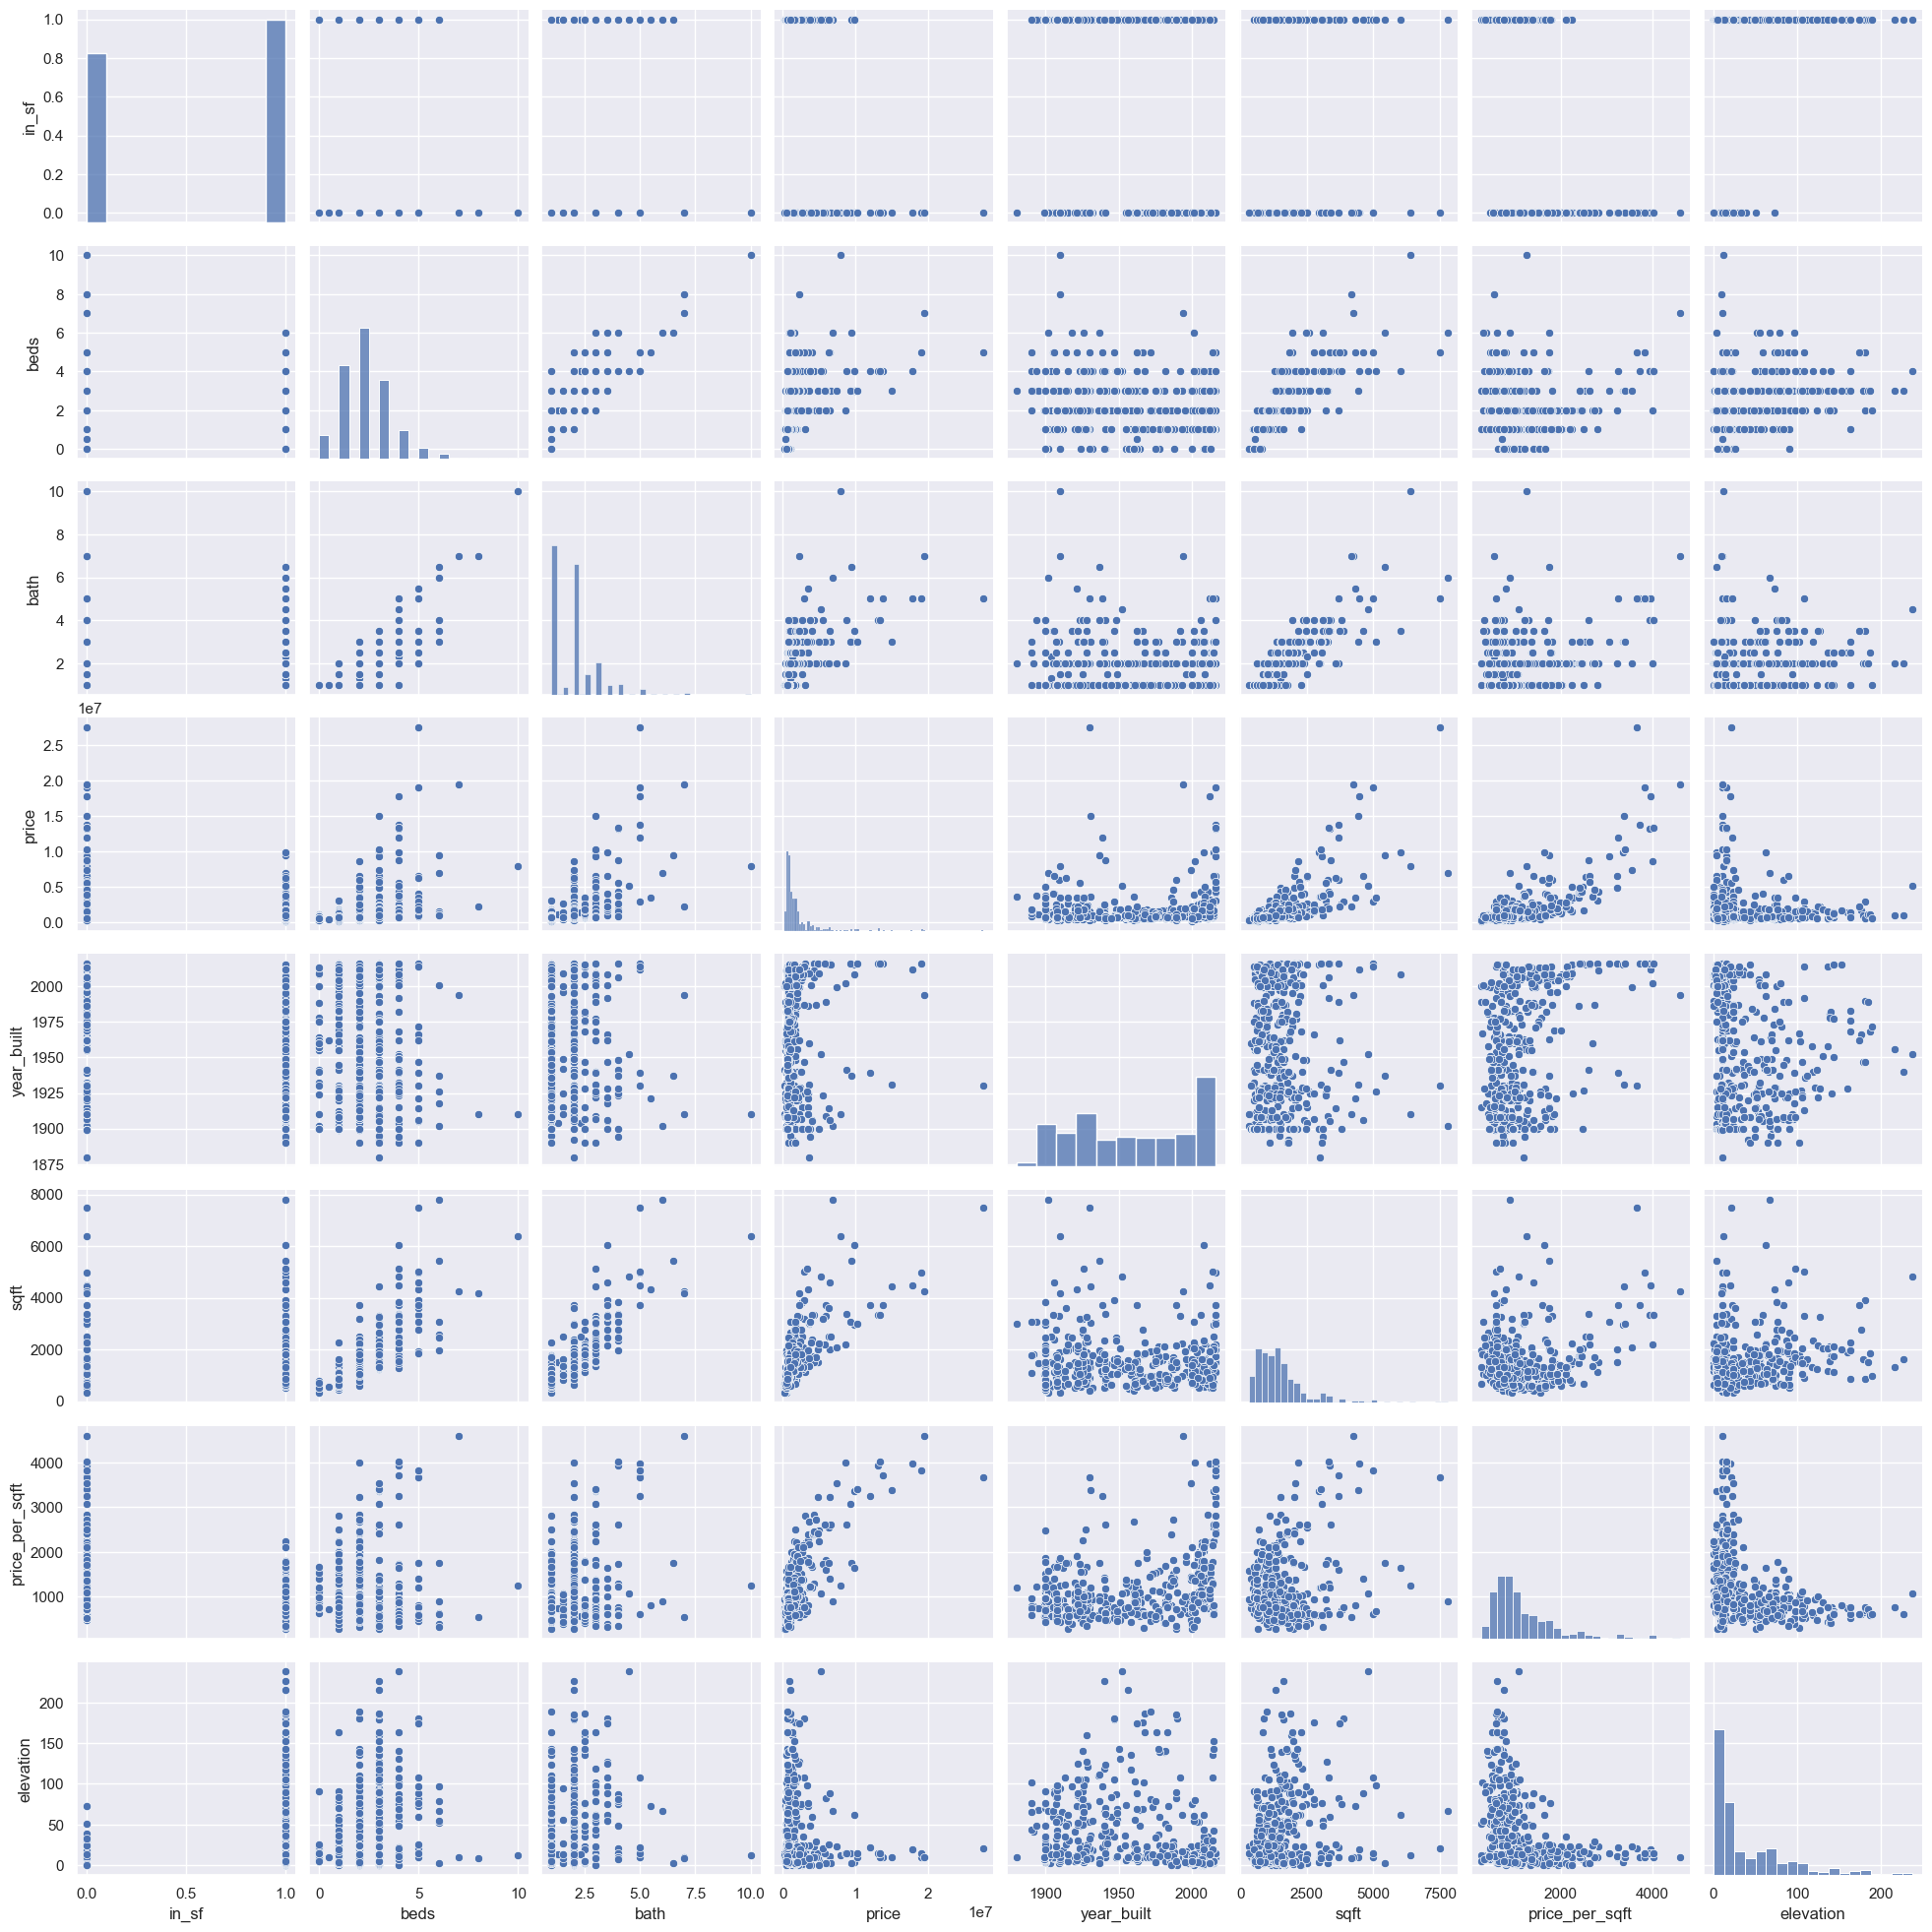

In [33]:
# 2. Visualize all the data using sns.pairplot.
sns.pairplot(df_houses)
plt.show()

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> Visualize all the data using sns.pairplot.</span></p>
</div>

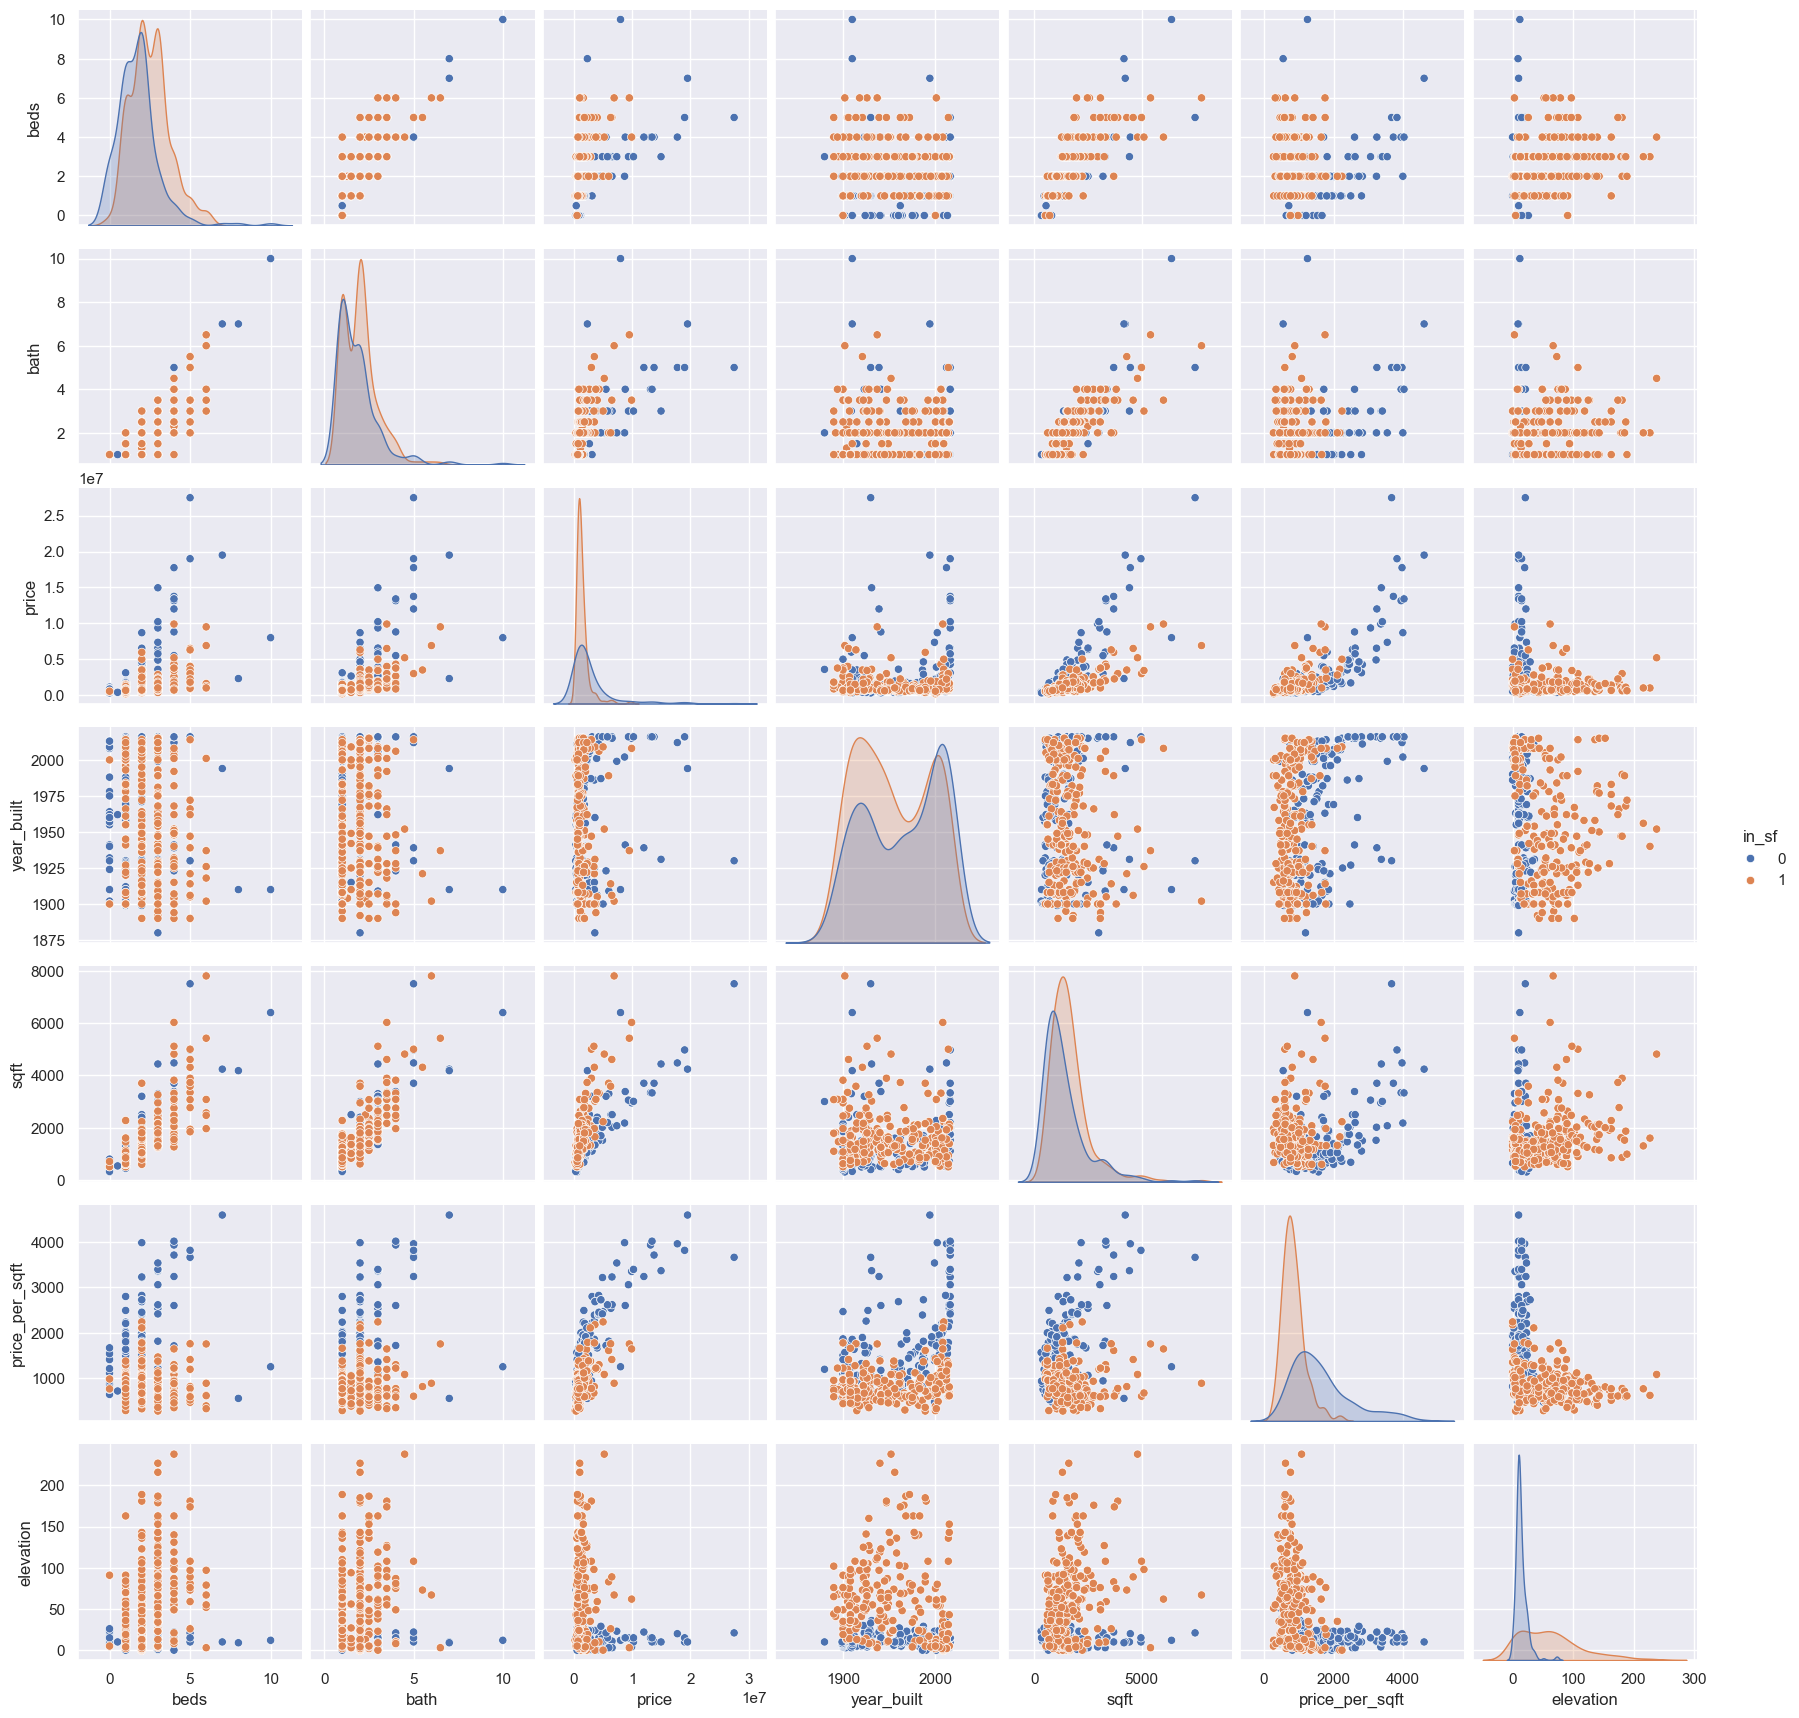

In [34]:
# Visualize all the data using sns.pairplot. (With target hue)
sns.pairplot(df_houses, hue='in_sf')
plt.show()

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Check for null values.</span></p>
</div>


In [35]:
# 3. Check for null values.
df_houses.isnull().sum()

in_sf             0
beds              0
bath              0
price             0
year_built        0
sqft              0
price_per_sqft    0
elevation         0
dtype: int64

## #2 Select and Engineer Features

1. Create a list of the features you are going to use.  In this case use as many or as little as you would like.
2. Define our `X` and `y`.
3. Split our data into trainig and testing sets.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Create a list of the features you are going to use.<br>2. Define our `X` and `y`.<br>3. Split our data into trainig and testing sets.</span></p>
</div>


In [36]:
# 1. Create a list of the features you are going to use.
selected_features = [col for col in df_houses.columns if col != 'in_sf']
# 2. Define our `X` and `y`.
X = df_houses[selected_features]
y = df_houses['in_sf']
# 3. Split our data into trainig and testing sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## #3 Build and Train Model

1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.  Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
3. Fit your GridSearchCV with your training data. 
4. Print the parameters of your best model. 


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.</span></p>
</div>


In [37]:
# 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2', None]
}

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.<br>Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.</span></p>
</div>


In [38]:
# 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.
#    Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Fit your GridSearchCV with your training data.</span></p>
</div>


In [39]:
# 3. Fit your GridSearchCV with your training data.
grid_search.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Print the parameters of your best model.<br>Print the best parameters it found.</span></p>
</div>


In [40]:
# 4. Print the parameters of your best model. 
#    Print the best parameters it found.
print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'max_depth': 10, 'max_features': None, 'min_samples_split': 5, 'n_estimators': 200}


## #4 Evaluate Model

1. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
2. Which feature was your most important feature?


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores.<br>What do you expect the best model from your search to be, and what will you try so you can evaluate it?<br>Now lets evaluate our model.<br>Calculate predicted probabilities, keep only probability for when class = 1.</span></p>
</div>


In [41]:
# 1. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
# This command gives you tree that has the highest f1-score.
rf_houses = grid_search.best_estimator_

# Now lets evaluate our model.
y_pred = rf_houses.predict(X_test)

# Calculate predicted probabilities, keep only probability for when class = 1.
y_prob = rf_houses.predict_proba(X_test)[:, 1]

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Accuracy:  0.8889
Precision: 0.8644
Recall:    0.9444
F1 Score:  0.9027
AUC Score: 0.9514


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Which feature was your most important feature?<br>Now lets look at our feature importances.</span></p>
</div>


In [42]:
# 2. Which feature was your most important feature?
#    Now lets look at our feature importances.
feature_importances = pd.DataFrame({
    'feature': selected_features,
    'importance': rf_houses.feature_importances_
}).sort_values('importance', ascending=False)

feature_importances

,feature,importance
6,elevation,0.523791
5,price_per_sqft,0.203766
3,year_built,0.144788
4,sqft,0.055512
2,price,0.044382
0,beds,0.016791
1,bath,0.010971


The most important feature is elevation, accounting for roughly 52.4% (0.523791) of the model's predictive power

In [43]:
df_houses_eng = df_houses.copy()

# Engineer real estate ratios (adding 1 to beds to avoid division by zero for studios)
df_houses_eng['sqft_per_bed'] = df_houses_eng['sqft'] / (df_houses_eng['beds'] + 1)
df_houses_eng['bath_per_bed'] = df_houses_eng['bath'] / (df_houses_eng['beds'] + 1)

# 1. Create a list of the features.
selected_features = [col for col in df_houses_eng.columns if col != 'in_sf']

# 2. Define our `X` and `y`.
X = df_houses_eng[selected_features]
y = df_houses_eng['in_sf']

# 3. Split our data into training and testing sets (keeping the exact same random_state=42).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [44]:
# 1. Expanded parameter grid with criterion and min_samples_leaf
param_grid = {
    'n_estimators': [100, 200, 300],
    'criterion': ['gini', 'entropy'],
    'max_depth': [6, 10, 15, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2', None]
}

# 2. Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

# 3. Fit GridSearchCV
grid_search.fit(X_train, y_train)

# 4. Print best parameters
print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'criterion': 'entropy', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}


In [45]:
# 1. Evaluate best model
rf_houses = grid_search.best_estimator_
y_pred = rf_houses.predict(X_test)
y_prob = rf_houses.predict_proba(X_test)[:, 1]

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Accuracy:  0.8990
Precision: 0.8966
Recall:    0.9286
F1 Score:  0.9123
AUC Score: 0.9589


In [46]:
feature_importances = pd.DataFrame({
    'feature': selected_features,
    'importance': rf_houses.feature_importances_
}).sort_values('importance', ascending=False)

feature_importances

,feature,importance
6,elevation,0.317160
5,price_per_sqft,0.215478
3,year_built,0.113881
2,price,0.105373
4,sqft,0.093667
7,sqft_per_bed,0.053804
0,beds,0.047959
8,bath_per_bed,0.033759
1,bath,0.018919


In the updated model with engineered real estate ratios, without stratifying data and without specifying criterion and minimum number of samples in a leaf, we achieved accuracy of 89.90 %. The importance of elevation fell down to 31.72% while other features remained about the same.

***
<h1 align="center"> <span style="color:#FFA500"> Which feature was your most important feature? </span> </h1>

***
<p style="text-align:center;">Write your answer in this cell after the table above.</p>


# Awesome difficult extra credit below:
Build a classifier using the adult_income.csv data.  
* The target variable is 'class'.
* Start with just using these features `selected_features = ['age', 'fnlwgt', 'capital_gain', 'capital_loss', 'hours_per_week']`
* You have to include the pos_label in your precision, recall, and f1 scores. It just tells the classifier which one is the posotive label.  I provided the proper way below.

* See if you can get above 50% f1 score.  
* See some [super tricks and tips here](https://www.kaggle.com/code/jieyima/income-classification-model)